# Módulo 5 — Transformações Box–Cox

## Seção 1 — Variância não constante, relações média–variância e motivação para transformações

**Estado editorial:** primeira versão para revisão matemática e pedagógica. **Pré-requisitos:** momentos, estacionariedade fraca, tendência e sazonalidade, logaritmos, derivadas elementares e simulação com NumPy. **Convenção:** $X_t$ denota uma observação positiva; $m_t=E[X_t]$; $	au>0$ denota desvio padrão na escala logarítmica. Todos os dados desta seção são **sintéticos**.

**Fontes e alcance.** O documento `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 5, determina o estudo da estabilização da variância antes da família Box–Cox. O `mapeamento-conteudos-series-temporais.md` registra a abordagem aplicada da transformação na *Aula 2 — Parte II — Decomposição STL e MSTL* e menciona sua cobertura parcial nas aulas de ARIMA. Esta seção é **complementação matemática e computacional original**; não atribuímos as deduções a páginas do livro acadêmico que não foram verificadas para este tópico. A estimação de $\lambda$ por verossimilhança, a transformação inversa de previsões e o viés ficam para seções posteriores.

### Objetivos de aprendizagem

Ao concluir, o leitor deverá: (i) diferenciar heterocedasticidade marginal, heterocedasticidade condicional e não estacionariedade da média; (ii) deduzir relações entre média e variância em modelos multiplicativos; (iii) explicar por que uma transformação pode reduzir a dependência da variância em relação ao nível; (iv) interpretar o método delta como aproximação local; (v) usar Python para distinguir variância entre trajetórias da variabilidade temporal de uma trajetória.

### 1. Motivação: quando a amplitude das oscilações cresce com o nível

Considere uma série de vendas, vazão de rio ou precipitação agregada que oscile pouco quando seu nível é baixo, mas apresente flutuações mais amplas quando o nível cresce. Uma possibilidade é que a variância de $X_t$ aumente com a média. Isso não é uma consequência automática da tendência: os dois conceitos precisam ser distinguidos.

No modelo aditivo

$$
X_t=m_t+\varepsilon_t,\qquad E[\varepsilon_t]=0,\quad \mathrm{Var}(\varepsilon_t)=\sigma^2,
$$

temos

$$
E[X_t]=m_t,\qquad \mathrm{Var}(X_t)=\sigma^2.
$$

A média pode variar com $t$ sem que a variância varie. A transformação não é justificada apenas porque existe uma tendência.

Em contraste, em um modelo de flutuação proporcional,

$$
X_t=m_t V_t,\qquad m_t>0,\qquad E[V_t]=1,\qquad \mathrm{Var}(V_t)=c>0,
$$

em que $m_t$ é determinístico, obtemos

$$
\begin{aligned}
E[X_t]&=m_t E[V_t]=m_t,\\
\mathrm{Var}(X_t)&=m_t^2\mathrm{Var}(V_t)=c m_t^2.
\end{aligned}
$$

Logo, o desvio padrão é $\sqrt c\,m_t$. Um aumento da média é acompanhado de aumento proporcional do desvio padrão, mesmo que a distribuição relativa de $V_t$ não mude.

### 2. Heterocedasticidade marginal e condicional não são sinônimos

- **Variância marginal dependente do tempo:** $\mathrm{Var}(X_t)=v_t$, com $v_t$ não constante. Isso viola uma das condições de estacionariedade fraca do processo original.
- **Variância condicional:** $\mathrm{Var}(X_t\mid\mathcal F_{t-1})$, com $\mathcal F_{t-1}$ representando as informações passadas. Ela pode variar mesmo quando a variância marginal é constante. Modelos ARCH/GARCH tratam desse fenômeno; não os desenvolveremos nesta seção.
- **Variabilidade por janelas:** o desvio padrão calculado em blocos de uma trajetória é uma estatística descritiva. Se a média apresentar tendência ou sazonalidade dentro da janela, esse cálculo mistura mudança de nível e ruído. Não é, sem hipóteses, uma estimativa da variância marginal em um instante fixo.

Uma transformação monótona $g(X_t)$ pode reduzir a dependência da dispersão em relação ao nível, mas não garante estacionariedade nem elimina dependência serial, raízes unitárias ou volatilidade condicional.

### 3. Uma dedução exata: o modelo lognormal com média controlada

Sejam $U_t$ independentes e normalmente distribuídos com

$$
U_t\sim N\left(-\frac{\tau^2}{2},\tau^2\right),\qquad \tau>0.
$$

Defina

$$
X_t=m_t\exp(U_t),\qquad m_t>0.
$$

O resultado elementar para uma variável normal $U\sim N(\mu,s^2)$ é

$$
E[\exp(aU)]=\exp\left(a\mu+\frac{a^2s^2}{2}\right).
$$

Esse resultado pode ser demonstrado por completar quadrados na integral da densidade normal; neste momento, utilizamo-lo como identidade conhecida e explicitamos seus parâmetros. Com $a=1$, resulta

$$
E[\exp(U_t)]=\exp\left(-\frac{\tau^2}{2}+\frac{\tau^2}{2}\right)=1.
$$

Logo, $E[X_t]=m_t$. Com $a=2$,

$$
E[\exp(2U_t)]=\exp(-\tau^2+2\tau^2)=\exp(\tau^2).
$$

Portanto,

$$
\begin{aligned}
\mathrm{Var}(X_t)
&=E[X_t^2]-E[X_t]^2\\
&=m_t^2\exp(\tau^2)-m_t^2\\
&=m_t^2\bigl[\exp(\tau^2)-1\bigr].
\end{aligned}
$$

Essa é uma relação **exata** para o modelo especificado, não uma aproximação. O coeficiente de variação é

$$
\mathrm{CV}(X_t)=\frac{\sqrt{\mathrm{Var}(X_t)}}{E[X_t]}=\sqrt{\exp(\tau^2)-1},
$$

constante em $t$, embora a variância não o seja quando $m_t$ varia.

Aplicando o logaritmo,

$$
Y_t=\log X_t=\log m_t+U_t.
$$

Assim,

$$
E[Y_t]=\log m_t-\frac{\tau^2}{2},\qquad \mathrm{Var}(Y_t)=\tau^2.
$$

A variância da série transformada tornou-se constante porque o modelo especifica erro **aditivo** na escala logarítmica. A média transformada ainda pode variar no tempo; portanto, a série $Y_t$ não se torna automaticamente fracamente estacionária.

**Exemplo numérico.** Se $\tau=0{,}2$, então $\tau^2=0{,}04$ e $\exp(0{,}04)-1\approx0{,}04081$. Para $m_t=10$, a variância original é aproximadamente $4{,}081$; para $m_t=20$, passa a aproximadamente $16{,}324$. Nas duas situações, a variância de $\log X_t$ vale exatamente $0{,}04$.

### 4. Método delta: a explicação local para a estabilização

Se $X$ se concentra em torno de $\mu=E[X]$ e $g$ possui derivada próxima de $\mu$, a expansão de Taylor de primeira ordem é

$$
g(X)\approx g(\mu)+g'(\mu)(X-\mu).
$$

Ao tomar variâncias, o termo constante desaparece:

$$
\boxed{\mathrm{Var}[g(X)]\approx[g'(\mu)]^2\mathrm{Var}(X).}
$$

Essa aproximação pressupõe dispersão relativamente pequena e regularidade da função perto de $\mu$; **não** é uma identidade geral.

Se a relação entre o desvio padrão e a média for, aproximadamente,

$$
\mathrm{DP}(X)\approx C\mu^p,
$$

então o objetivo $\mathrm{DP}[g(X)]\approx\text{constante}$ sugere escolher $g'(\mu)\propto\mu^{-p}$. Integrando,

$$
g(x)\propto
\begin{cases}
\dfrac{x^{1-p}}{1-p},&p\ne1,\\
\log x,&p=1.
\end{cases}
$$

A família Box–Cox, estudada na próxima seção, contém justamente esse tipo de função, com parâmetro aproximado $\lambda=1-p$. O resultado é **heurístico** quando aplicado a séries reais: autocorrelação, efeitos sazonais, assimetria e suporte dos dados podem exigir outros cuidados.

### 5. Python integrado — comparar dispersão temporal e entre trajetórias

**Bibliotecas:** NumPy representa vetores e matrizes e gera valores pseudoaleatórios; Matplotlib desenha séries e comparações. O gerador `default_rng(2026)` torna o experimento reproduzível, mas não transforma simulação em demonstração.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
n = 240
t = np.arange(n)
tau = 0.18
m = 10 * np.exp(0.007 * t) * (1 + 0.18 * np.sin(2*np.pi*t/12))
u = rng.normal(-tau**2/2, tau, size=n)
x = m * np.exp(u)
y = np.log(x)

# A amostra é uma única trajetória; não contém 240 trajetórias.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(t, x)
ax[0].plot(t, m, linestyle='--')
ax[0].set(title='Escala original', xlabel='Tempo (meses)', ylabel='Índice sintético')
ax[1].plot(t, y)
ax[1].set(title='Escala log', xlabel='Tempo (meses)', ylabel='log(índice)')
plt.tight_layout()
plt.show()


O fator $m_t$ produz crescimento e sazonalidade determinísticos, e o fator $\exp(U_t)$ produz flutuações proporcionais. O gráfico mostra uma única realização: não permite medir diretamente $\mathrm{Var}(X_t)$ em cada instante.

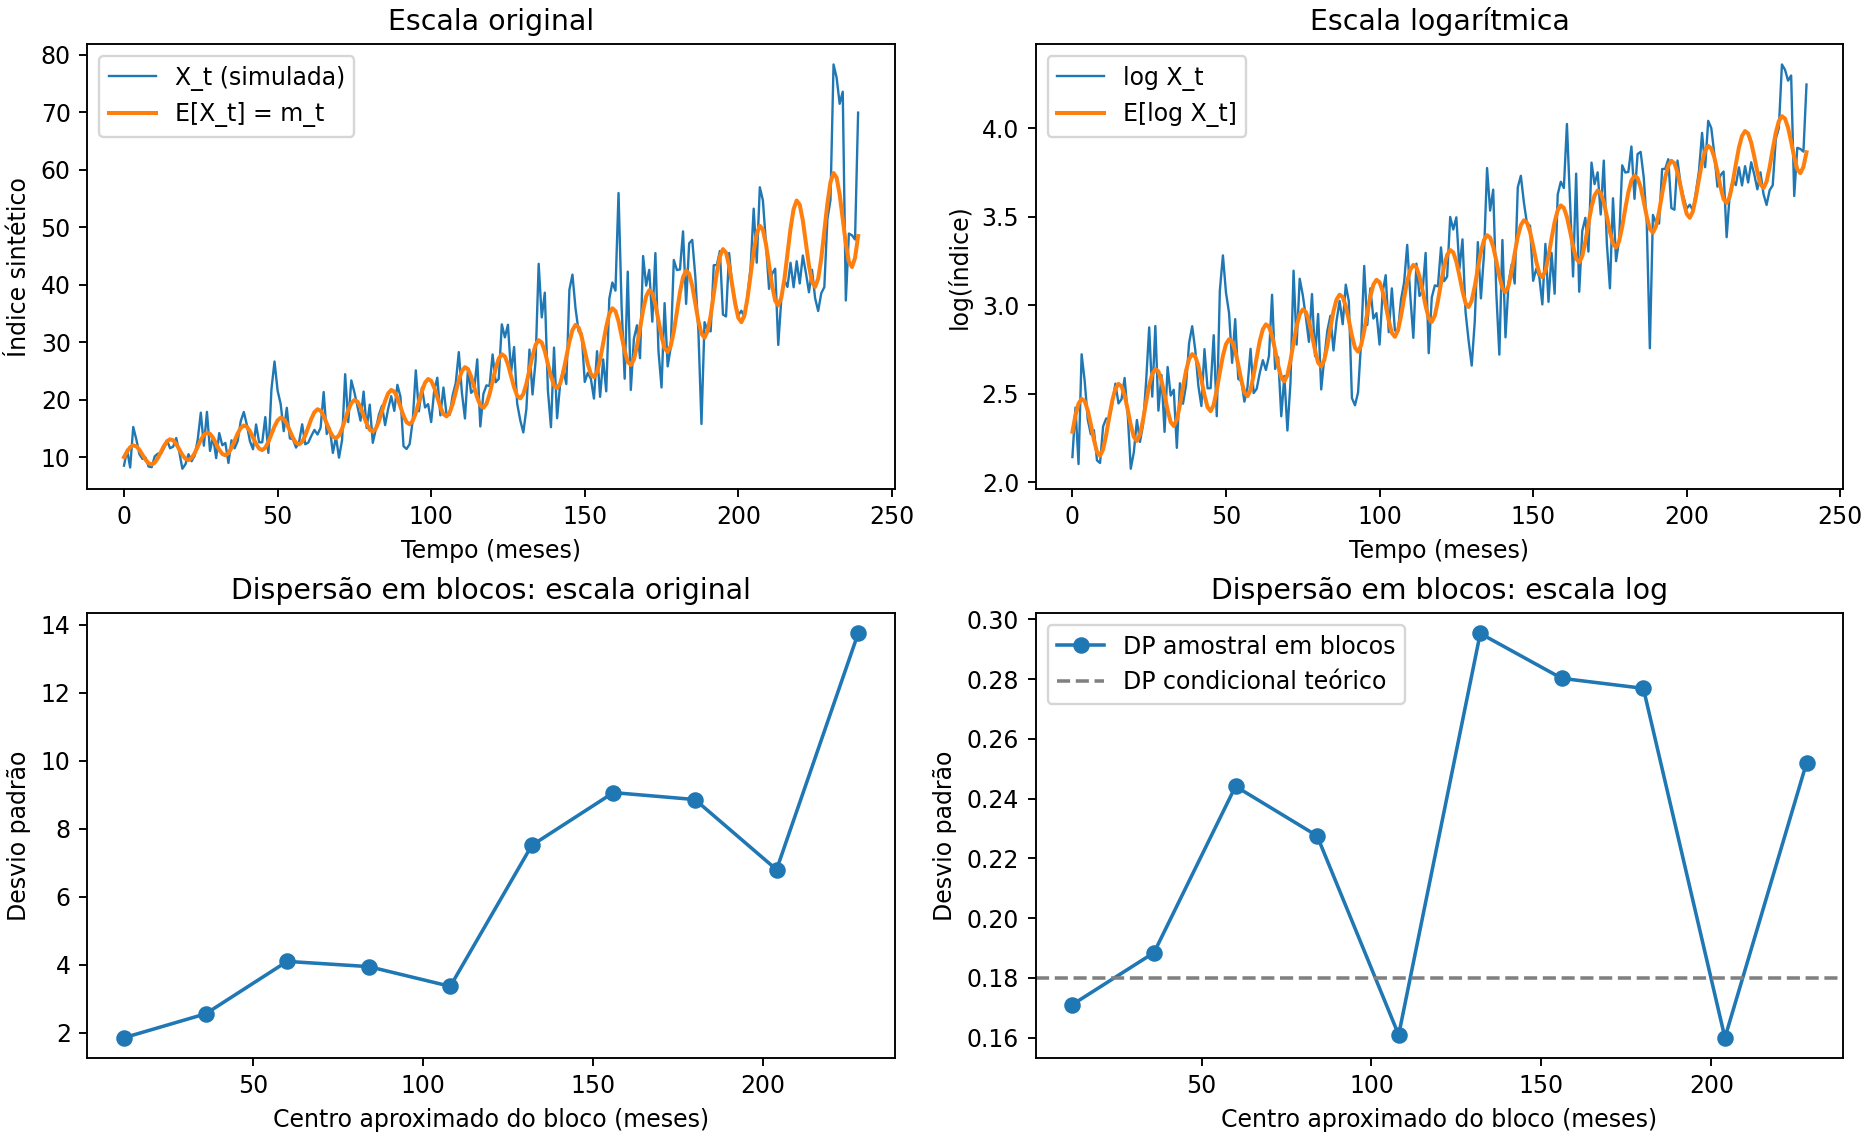

*Figura 1 — Série positiva simulada e sua escala logarítmica. Os desvios em blocos de 24 meses misturam sazonalidade e ruído; a linha horizontal no painel final mostra $\tau$, não uma identidade obrigatória para o desvio calculado em blocos.*

Para aproximar as variâncias **em instantes fixos**, simulamos $M$ trajetórias independentes do **mesmo processo** e calculamos a variância em cada coluna:

In [ ]:
rng = np.random.default_rng(492)
M = 5000
u_sim = rng.normal(-tau**2/2, tau, size=(M, n))
x_sim = m[None, :] * np.exp(u_sim)
var_x_est = x_sim.var(axis=0, ddof=1)
var_log_est = np.log(x_sim).var(axis=0, ddof=1)

var_x_teor = m**2 * np.expm1(tau**2)
var_log_teor = np.full(n, tau**2)

print(np.max(np.abs(var_log_est - var_log_teor)))


`m[None, :]` possui formato $(1,n)$; o NumPy o combina com a matriz $(M,n)$ por *broadcasting*. `axis=0` agrega as linhas em cada instante (não calcula a variabilidade temporal de uma trajetória). `ddof=1` utiliza divisor $M-1$ na variância amostral. Esperamos discrepâncias finitas em relação à teoria, mesmo com milhares de trajetórias.

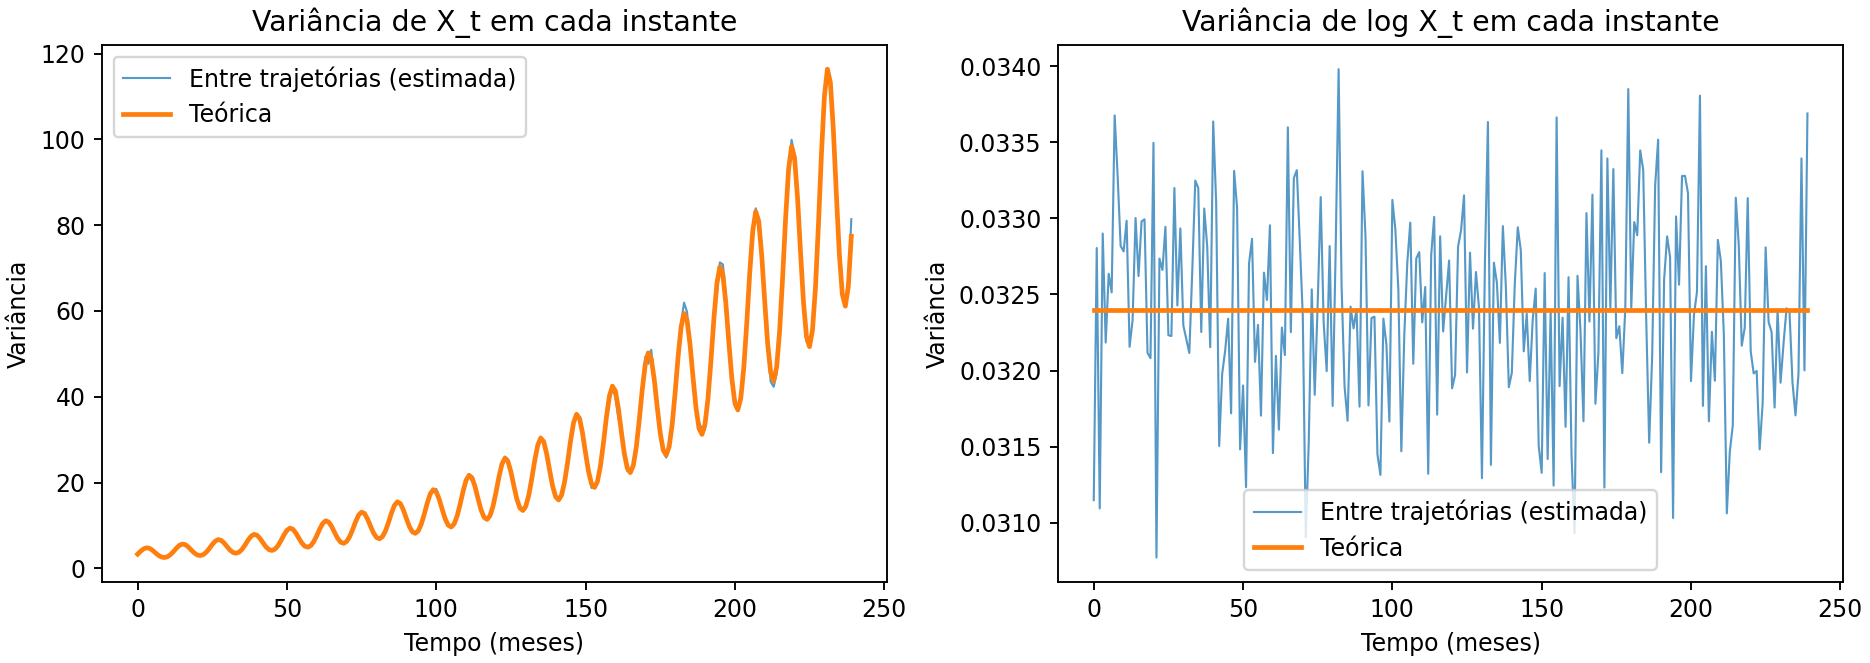

*Figura 2 — Variância estimada entre 5.000 trajetórias, por instante, confrontada com a expressão teórica. A variância na escala original acompanha $m_t^2$, enquanto a variância de $\log X_t$ permanece próxima de $\tau^2=0{,}0324$.*

**Limite prático:** séries meteorológicas reais geralmente fornecem uma trajetória histórica por estação; não dispomos de milhares de trajetórias independentes. Por isso, o experimento separa conceitos teóricos, mas sua estratégia de estimação não pode ser transplantada ingenuamente para uma única série real.

### 6. Quando não transformar

Não se deve transformar automaticamente séries que já tenham dispersão aproximadamente estável; nem supor que logaritmo ou Box–Cox sejam adequados para observações negativas, zero frequente, precipitação intermitente ou dados em que a escala original seja essencial. Uma transformação pode alterar a interpretação de diferenças, tendências, resíduos, estimativas e previsões. Precipitação ausente não é precipitação zero, e valores realmente nulos exigem tratamento explícito antes de usar logaritmos.

### 7. Exercícios

1. **Conceitual:** explique por que média crescente não implica variância crescente. Dê um contraexemplo algébrico.
2. **Demonstração:** deduza $\mathrm{Var}(m_tV_t)=m_t^2\mathrm{Var}(V_t)$, indicando a hipótese de $m_t$ determinístico.
3. **Numérico:** no modelo lognormal anterior, com $\tau=0{,}1$, calcule a razão $\mathrm{Var}(X_t\mid m_t=20)/\mathrm{Var}(X_t\mid m_t=10)$.
4. **Computacional:** varie `tau` no código e compare a variância teórica com a estimada entre trajetórias. Indique quais resultados se aproximam mais quando $M$ cresce.
5. **Interpretação:** por que o desvio padrão calculado em janelas de uma série com sazonalidade não estima necessariamente a variância marginal em um instante?

**Orientações selecionadas.** No exercício 3, a razão é $4$, pois a variância é proporcional a $m_t^2$. No exercício 5, a janela reúne instantes com médias diferentes, acrescentando dispersão devida à estrutura determinística.

### Síntese

O motivo de transformar não é remover uma tendência, e sim, sob hipóteses adequadas, aproximar uma estrutura de dispersão mais estável e melhorar a interpretação/modelagem de erros. A transformação logarítmica funciona exatamente no exemplo multiplicativo lognormal, mas não constitui solução universal para heterocedasticidade.

### Referências e rastreabilidade

- `PLANO_MODULOS_PRIORITARIOS.md`, **Módulo 5**: objetivos, cautelas e sequência pedagógica (fonte de planejamento efetivamente consultada).
- `mapeamento-conteudos-series-temporais.md`, **Aula 2 — Parte II** e tabela de cobertura **Box–Cox: parcial** (fonte do acervo didático efetivamente consultada).
- Morettin, P. A.; Toloi, C. M. C. *Análise de Séries Temporais: modelos lineares univariados*, vol. 1, 3. ed. Referência geral do projeto; **nenhuma dedução desta seção é atribuída a páginas não conferidas do livro**.
- Modelo multiplicativo lognormal, método delta, figuras, implementação e exercícios: **complementações didáticas originais**, apresentadas com suas hipóteses.